In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<Axes: xlabel='x', ylabel='y'>

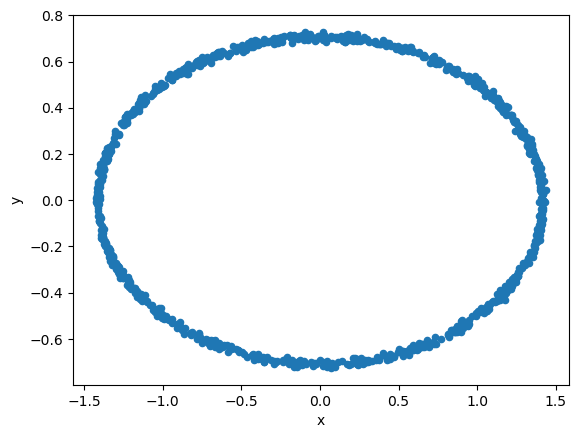

In [77]:
ellipse = pd.read_csv('HW2_ellipse.csv', header=None).rename(columns={0: 'x', 1: 'y'})
ellipse.plot.scatter(x='x', y='y')

In [93]:
A = (ellipse[['x', 'y']].to_numpy())**2
b = np.ones(ellipse.shape[0])
a = np.array([0, 0])
eta = (2 * np.linalg.norm(A.T @ A, 2))**-1

def loss(a, A, b):
    return np.linalg.norm(A @ a - b, 2)**2

last_loss = float('inf')
current_loss = loss(a, A, b)

while abs(last_loss - current_loss) > 1e-10:
    last_loss = current_loss
    a = a - 2 * eta * A.T @ (A @ a - b)
    current_loss = loss(a, A, b)

In [98]:
a, loss(a, A, b)

(array([0.50012491, 1.99463229]), np.float64(0.4641019952012522))

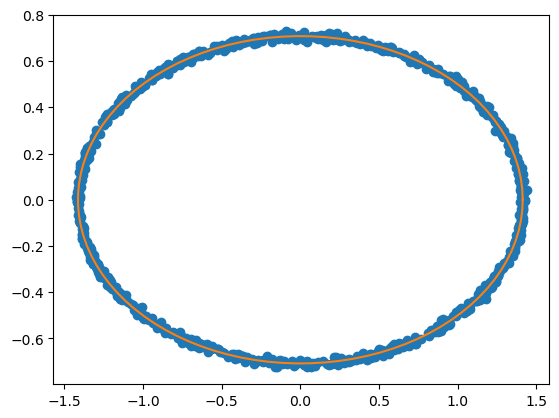

In [99]:
t = np.linspace(0, 2 * np.pi, 100)
plt.plot(ellipse['x'], ellipse['y'], 'o')
plt.plot(np.sqrt(1/a[0]) * np.cos(t), np.sqrt(1/a[1]) * np.sin(t))
plt.show()